# Time Series Forecasting

Grid operators must know tomorrow's electricity demand to schedule power plants; a factory plans shifts based on forecast orders; an energy manager wants to know the peak load of next week. All of these are **forecasting** problems on time series – sequences of measurements ordered in time.

Time series differ from the tabular data of the previous chapters in one fundamental way: the observations are not independent. Today's load is strongly related to yesterday's and to the load one week ago. This dependence is what makes forecasting possible – and it changes the rules for model validation. The single most common mistake in practical forecasting is to evaluate a model with information it would not have had at forecast time.

::: {.scenario}
**Scenario: a better day-ahead forecast?**

The planning department of a transmission system operator currently forecasts tomorrow's daily load with the seasonal naive method: "same as the same weekday last week". Forecast errors must be balanced with expensive reserve power. A data scientist proposes a gradient boosting model with lags and calendar features. Changing the operational forecasting process costs effort, so the head of planning sets a condition: the new model must reduce the mean absolute error by at least 10 % over a full year.

**Your decision:** Replace the seasonal naive forecast with the model?
:::

**Learning goals.** After this chapter you can

- describe a time series by trend, seasonality and noise, and analyse it with the autocorrelation function,
- define the forecasting task precisely (horizon, available information) and build naive and seasonal-naive baselines,
- turn forecasting into a regression problem with lag, calendar and exogenous features,
- validate forecasts correctly in time and compare them with MAE, RMSE and MAPE,
- (extension) fit seasonal ARIMA (SARIMA) models.

**Datasets in this chapter**

- [Open Power System Data – Time Series](https://data.open-power-system-data.org/time_series/)
- [DWD Climate Data Center](https://opendata.dwd.de/climate_environment/CDC/)

## Components and autocorrelation

A time series $y_1, y_2, \dots, y_T$ is often thought of as a combination of

- a **trend** (slow change of the level, e.g. growing electrification),
- one or several **seasonal** patterns (daily, weekly, yearly cycles),
- **exogenous** influences (temperature, holidays, production plans),
- and an irregular **noise** component.

::: {.callout-note}
## Definition: Autocorrelation function (ACF)
The autocorrelation at lag $h$ is the correlation of the series with itself shifted by $h$ time steps:
$$\rho(h) = \frac{\text{Cov}(y_t, y_{t-h})}{\text{Var}(y_t)}.$$
Peaks of the ACF at lags 7, 14, 21 (for daily data) indicate a weekly cycle; a slow decay indicates a trend or strong persistence.
:::

Many classical models assume **stationarity**: mean, variance and autocorrelation do not change over time. Trends and seasonal patterns violate this; **differencing** ($y_t - y_{t-1}$, or $y_t - y_{t-7}$ for a weekly season) removes them.

## Defining the forecasting task

Before choosing a model, answer three questions:

1. **Horizon:** how far ahead must we forecast – one hour, one day, one week?
2. **Information set:** which data are available *at the time the forecast is made*? Yesterday's load is known for a day-ahead forecast; today's load is not.
3. **Granularity and metric:** hourly or daily values? Which error matters – average error, peaks, under- or overestimation?

::: {.callout-note}
## Definition: Forecast error metrics
For forecasts $\hat y_t$ and actual values $y_t$ over a test period:
$$\text{MAE} = \frac1n\sum_{t}|y_t - \hat y_t|, \qquad \text{RMSE} = \sqrt{\frac1n\sum_{t}(y_t - \hat y_t)^2}, \qquad \text{MAPE} = \frac1n\sum_{t}\left|\frac{y_t - \hat y_t}{y_t}\right|,$$
where the sums run over the $n$ time steps of the test period.
RMSE penalises large errors more strongly; MAPE is scale-free but undefined for $y_t = 0$.
:::

::: {.callout-tip}
## Engineering practice: always compare with naive forecasts
The **naive** forecast predicts the last observed value; the **seasonal naive** forecast predicts the value one season ago (e.g. the same weekday last week). They are free, robust and surprisingly hard to beat. A sophisticated model that does not clearly outperform the seasonal naive forecast is not worth its complexity.
:::

## Forecasting as regression

The most flexible approach in practice: build a table in which each row is one time step and the columns contain information available at forecast time – **lagged values** ($y_{t-1}$, $y_{t-7}$, …), **rolling statistics** (mean of the last 7 days), **calendar features** (weekday, month, holiday) and **exogenous variables** (temperature forecast). Any regression method from the previous chapters can then be used; gradient boosting is a strong default.

::: {.callout-warning}
## Pitfall: information from the future
- **Random splits** put future observations into the training set and past observations into the test set. The model then "interpolates" instead of forecasting, and the error is unrealistically small.
- **Lags shorter than the horizon:** for a forecast 24 hours ahead, the lag 1 hour is not available at forecast time.
- **Measured instead of forecast exogenous data:** training with the *measured* temperature of tomorrow overstates the accuracy – in operation only a weather *forecast* is available.
:::

![Time series cross-validation with an expanding window. The model is always trained on the past (blue) and tested on the period that immediately follows (orange). In a random split (bottom), test observations are surrounded by training observations from before and after.](images/ts-split.png){#fig-tssplit width=90%}

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import importlib.util, subprocess, sys
for pkg in ["statsmodels", "holidays"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
#| code-fold: false
# Download helper, as in Chapter 2
from pathlib import Path
import requests

DATA = Path("data")
DATA.mkdir(exist_ok=True)                         # create the folder ./data if it does not exist

def download(url, fname=None):
    """Download a file once and cache it in ./data."""
    if fname is None:                             # no file name given:
        fname = url.split("/")[-1]                # use the last part of the URL
    path = DATA / fname                           # "/" joins folder and file name
    if not path.exists():                         # download only if not cached yet
        r = requests.get(url, timeout=300)        # give up after 300 s without response
        r.raise_for_status()                      # stop with an error if the download failed
        path.write_bytes(r.content)               # open, write and close the file in one step
    return path

## Live coding: German electricity load

The Open Power System Data (OPSD) time series package collects load, wind and solar generation and prices for 32 European countries from the ENTSO-E Transparency Platform and other sources. We use version 2020-10-06 (2015 to mid-2020) and only the column with the actual German load. The full CSV file is about 124 MB; we read only the two columns we need.

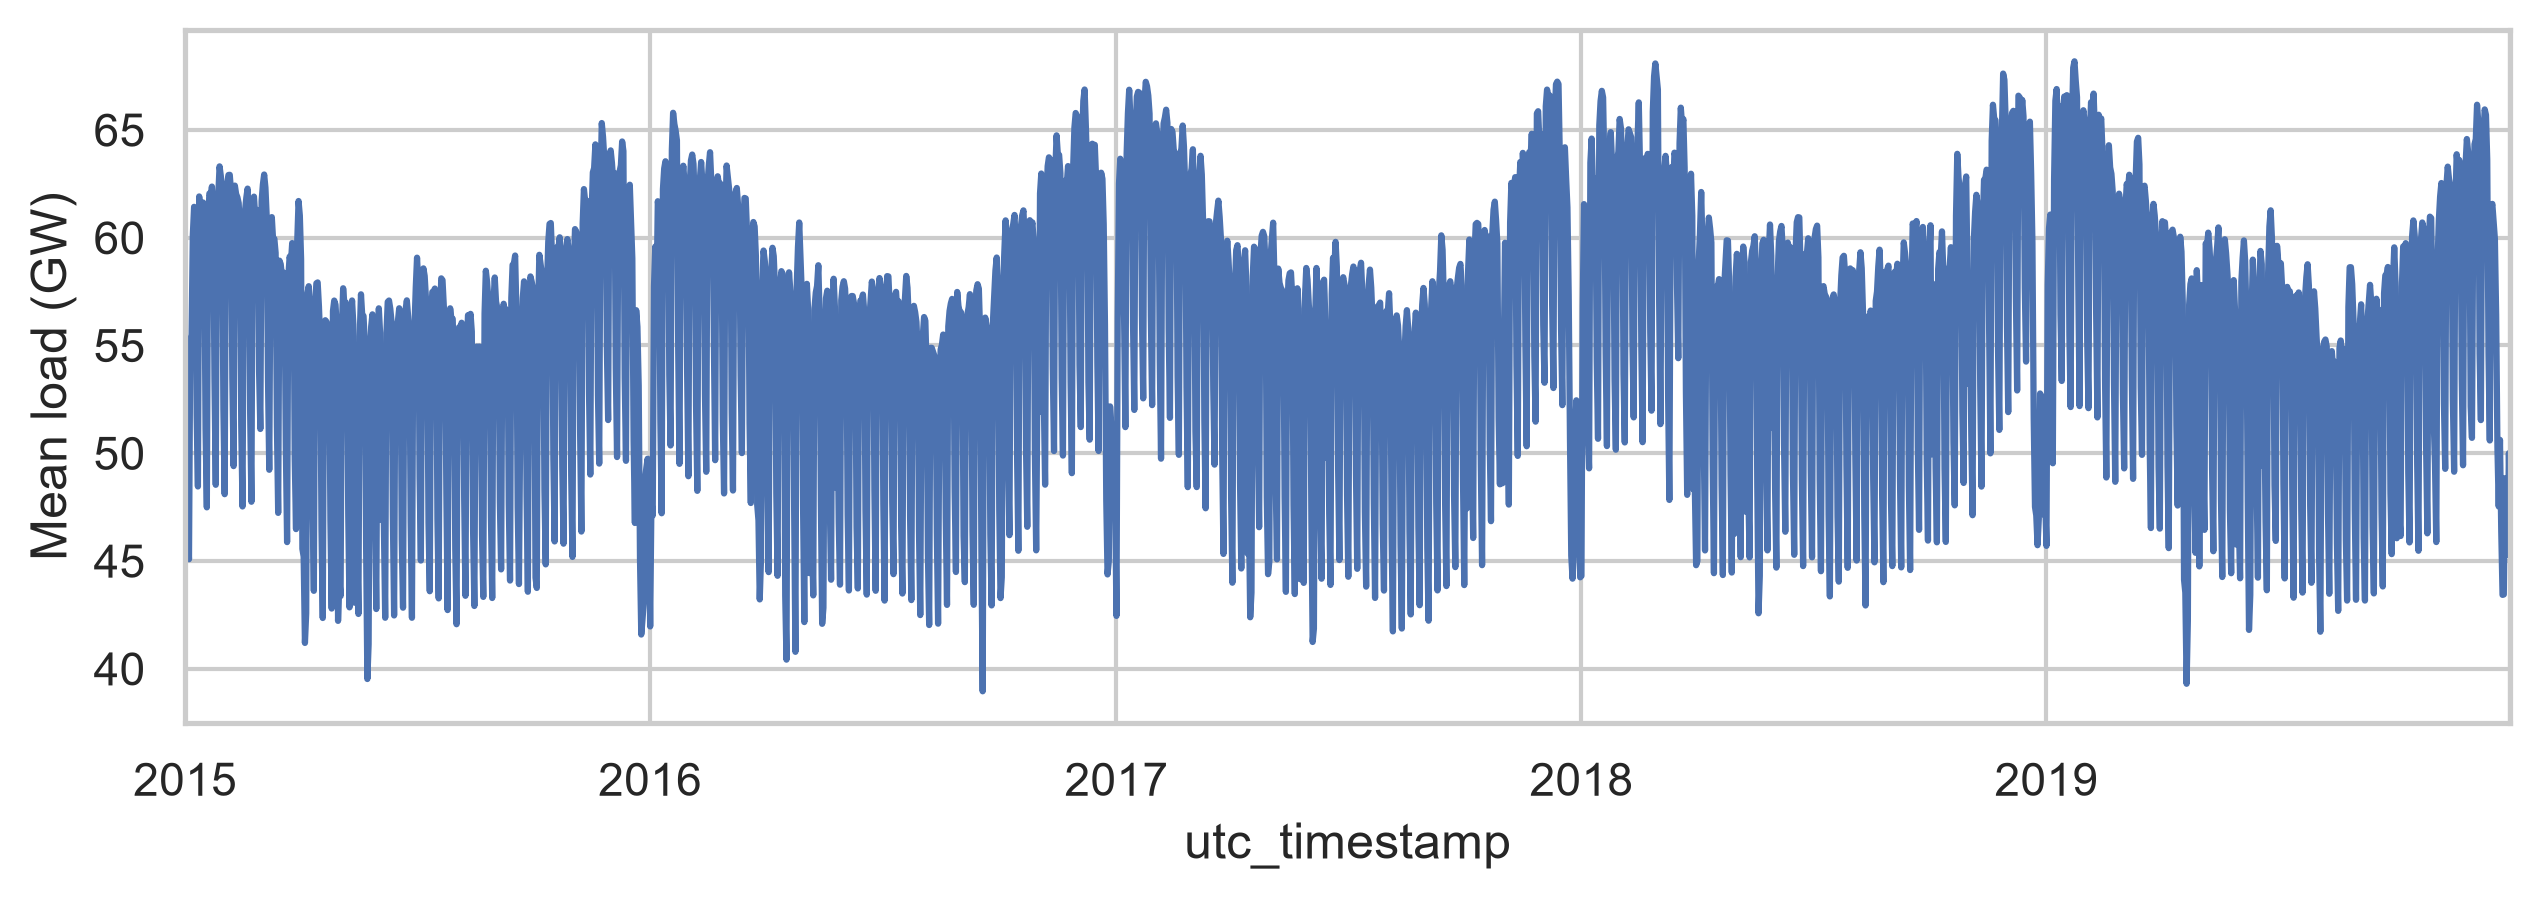

In [3]:
#| code-fold: false
url = ("https://data.open-power-system-data.org/time_series/2020-10-06/"
       "time_series_60min_singleindex.csv")
load = pd.read_csv(download(url), usecols=["utc_timestamp", "DE_load_actual_entsoe_transparency"],
                   parse_dates=["utc_timestamp"], index_col="utc_timestamp")
load = load.rename(columns={"DE_load_actual_entsoe_transparency": "load_MW"})["load_MW"]
daily = load.resample("D").mean().loc["2015-01-01":"2019-12-31"] / 1000   # GW
ax = daily.plot(figsize=(10, 3), ylabel="Mean load (GW)")
plt.show()

**Discussion.** The daily mean load shows a yearly cycle (higher in winter: lighting, heating), a strong weekly cycle (lower on weekends) and sharp drops around Christmas and public holidays. We restrict ourselves to 2015–2019 to avoid the exceptional Covid-19 period of 2020 – a reminder that structural breaks can make historical data unrepresentative.

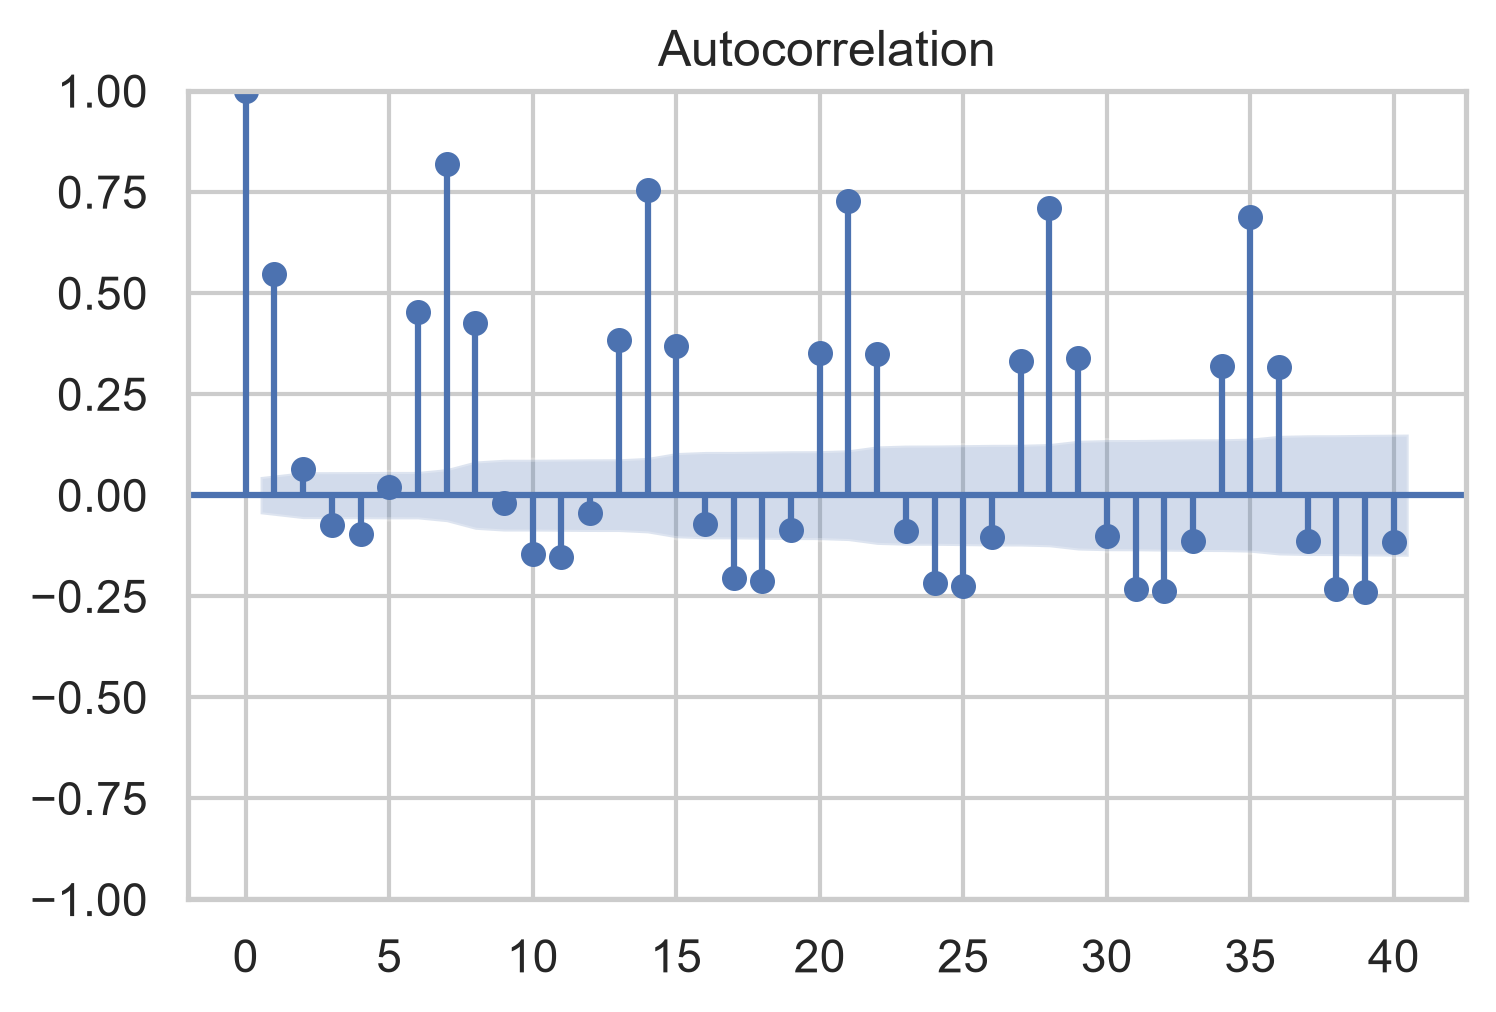

In [4]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(daily, lags=40); plt.show()

The ACF has pronounced peaks at lags 7, 14, 21, … – the weekly cycle – and decays slowly overall, reflecting the yearly cycle and persistence.

### Baselines

We forecast each day of the test period one day ahead (horizon 1 day) and use the last year as test period.

In [5]:
#| code-fold: false
test_start = "2019-01-01"
y_test = daily[test_start:]
naive = daily.shift(1)[test_start:]                 # yesterday
seasonal_naive = daily.shift(7)[test_start:]        # same weekday last week

def report(name, pred):
    err = y_test - pred
    print(f"{name:22s} MAE = {err.abs().mean():.2f} GW,  MAPE = {(err.abs() / y_test).mean():.1%}")

report("naive (yesterday)", naive)
report("seasonal naive (t-7)", seasonal_naive)

naive (yesterday)      MAE = 4.31 GW,  MAPE = 8.0%
seasonal naive (t-7)   MAE = 2.30 GW,  MAPE = 4.3%


The naive forecast fails at every weekday/weekend transition; the seasonal naive forecast handles these well and fails mainly on holidays and around them.

### Feature-based forecasting with gradient boosting

In [6]:
#| code-fold: false
import holidays
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

df = daily.to_frame("load")
for lag in (1, 7, 14):
    df[f"lag_{lag}"] = df["load"].shift(lag)
df["dow"] = df.index.dayofweek
df["doy"] = df.index.dayofyear
de_holidays = holidays.Germany(years=range(2015, 2021))
df["holiday"] = [d.date() in de_holidays for d in df.index]
df = df.dropna()

X, y = df.drop(columns="load"), df["load"]
gbr = HistGradientBoostingRegressor(random_state=0)
scores = cross_val_score(gbr, X, y, cv=TimeSeriesSplit(5), scoring="neg_mean_absolute_percentage_error")
print("MAPE per fold (time series CV):", np.round(-scores, 3))

gbr.fit(X[:test_start].iloc[:-1], y[:test_start].iloc[:-1])
report("gradient boosting", pd.Series(gbr.predict(X[test_start:]), index=X[test_start:].index))

MAPE per fold (time series CV): [0.032 0.029 0.018 0.016 0.016]


gradient boosting      MAE = 0.88 GW,  MAPE = 1.6%


**Discussion.** All features are available at forecast time: lags 1, 7 and 14 days, the calendar and the holiday calendar, which is known in advance. `TimeSeriesSplit` trains on an expanding window and always tests on the following block; the error per fold shows how stable the model is over time. The comparison with the baselines on the same test year shows how much the model really adds.

**Weather as an input.** Temperature drives heating and cooling demand. Historical hourly temperatures are available from the DWD (see Chapter 2 and Exercise 2). For a real day-ahead forecast, the model must be trained and operated with temperature *forecasts* – using measured temperatures overstates the accuracy.

## Back to the decision

We compare both methods on the test year 2019, which was not used for training. The model must reduce the MAE by at least 10 %.

In [7]:
#| code-fold: false
pred_gb = pd.Series(gbr.predict(X[test_start:]), index=X[test_start:].index)
common = pred_gb.index.intersection(seasonal_naive.dropna().index)
mae_naive = (y_test[common] - seasonal_naive[common]).abs().mean()
mae_model = (y_test[common] - pred_gb[common]).abs().mean()
gain = 1 - mae_model / mae_naive
print(f"MAE seasonal naive: {mae_naive:.2f} GW,  MAE gradient boosting: {mae_model:.2f} GW,  improvement: {gain:.0%}")
print("Decision:", "replace the seasonal naive forecast." if gain >= 0.10 else "keep the seasonal naive forecast.")

MAE seasonal naive: 2.30 GW,  MAE gradient boosting: 0.88 GW,  improvement: 62%
Decision: replace the seasonal naive forecast.


A one-year test is a good basis, but the recommendation should add: the improvement comes mainly from holidays and transitions – check the error on those days separately; the model should be monitored after go-live, because structural changes (such as the drop in demand in 2020) can make it worse than the simple method; and adding temperature forecasts (Exercise 2) is the obvious next step.

## Extension: seasonal ARIMA

*Extension – optional material, not required for the exam.*

ARIMA models describe a series by its own past values (**AR**, autoregressive part), past forecast errors (**MA**, moving average part) after differencing $d$ times (**I**, integrated). The seasonal extension SARIMA$(p,d,q)(P,D,Q)_s$ adds the same terms at the seasonal lag $s$ (here $s = 7$ days). ARIMA models are the classical statistical approach: compact, with well-founded prediction intervals, but harder to extend with many exogenous variables than the regression approach.

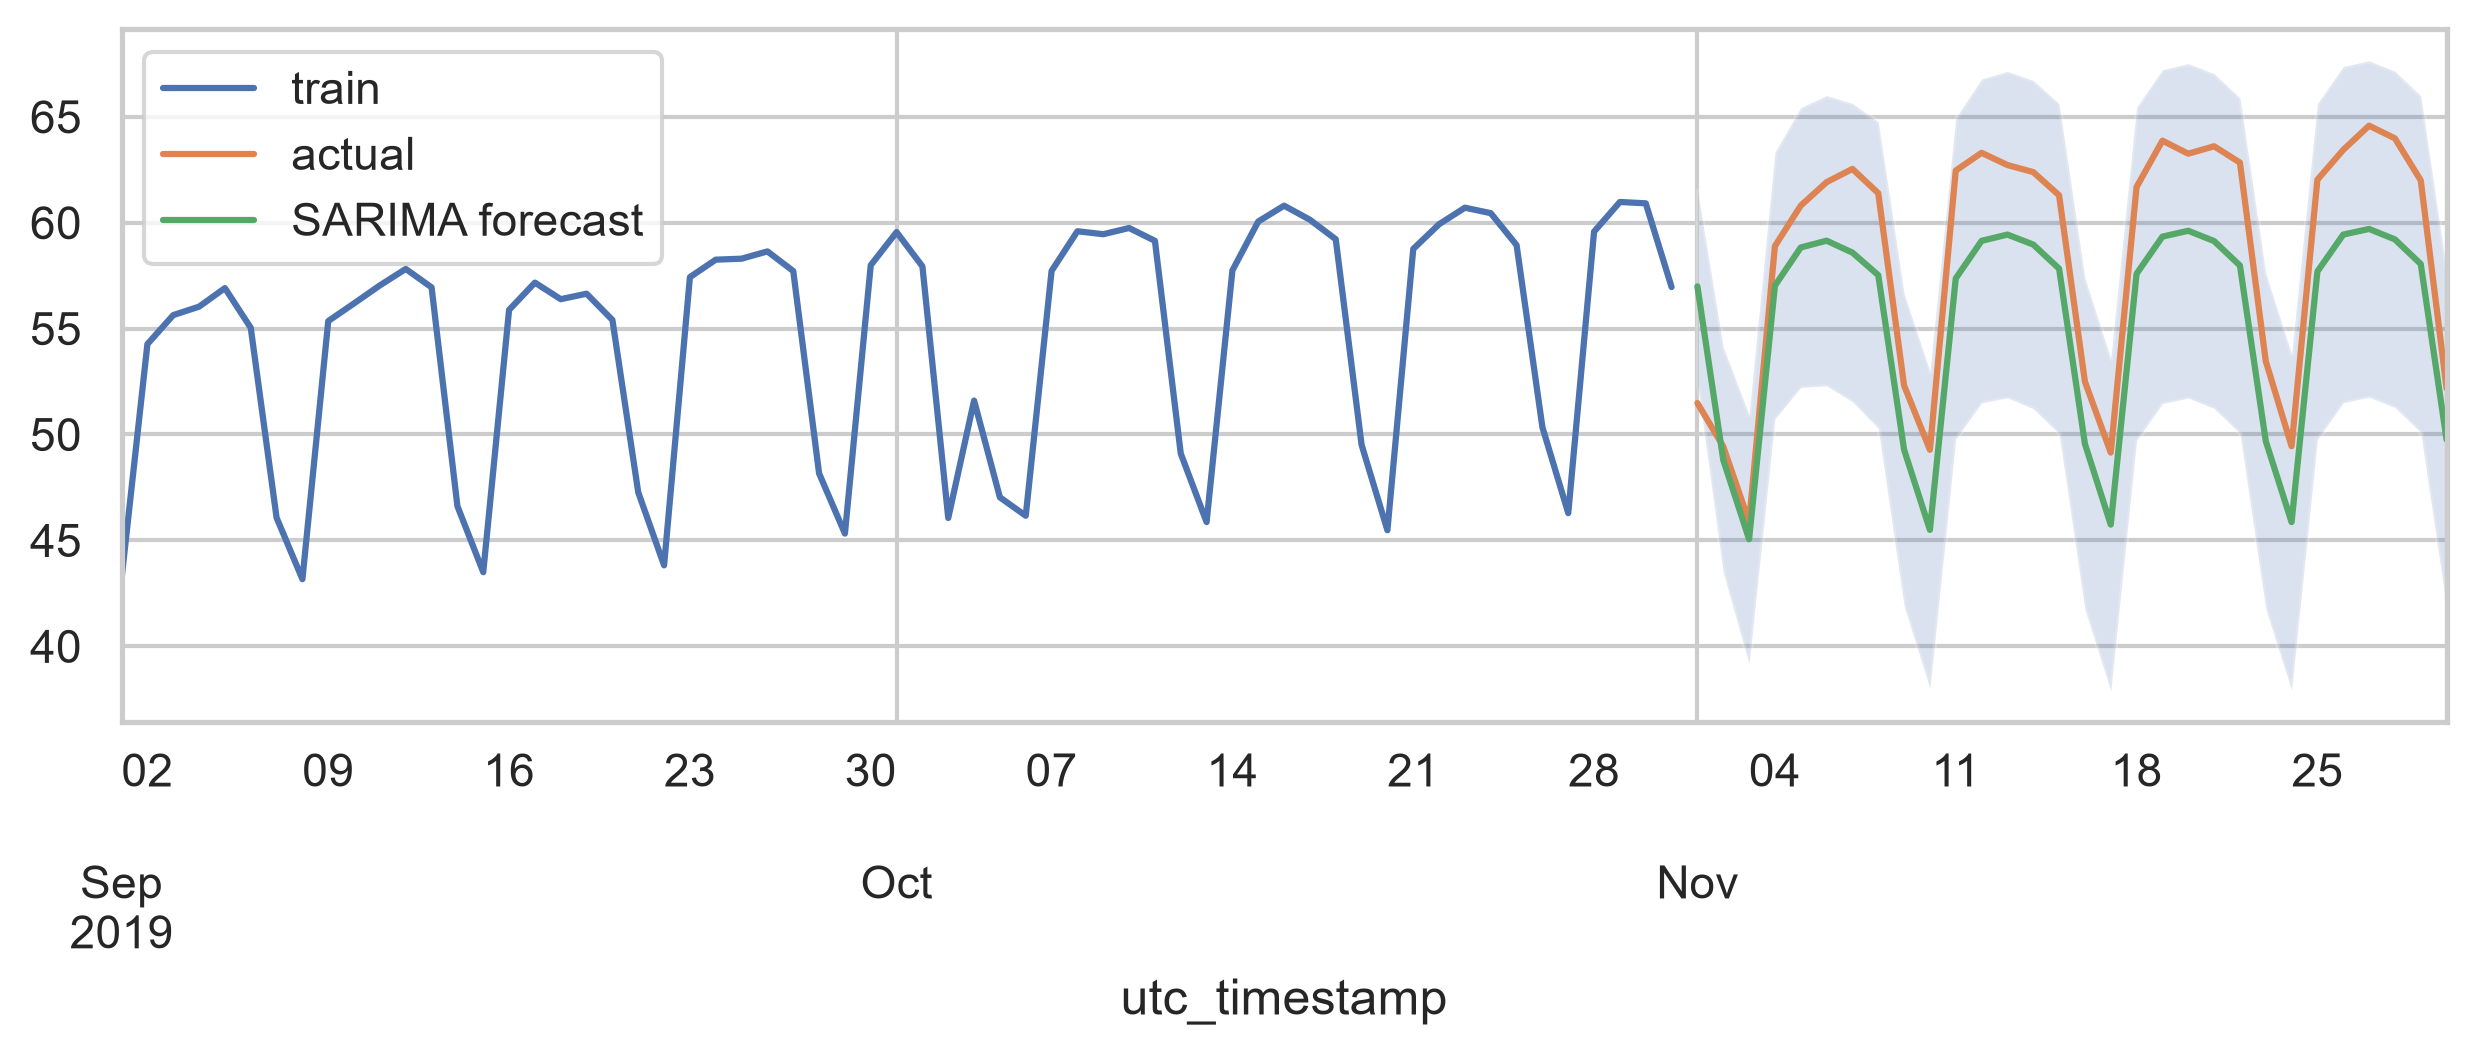

MAPE November 2019 (forecast up to 30 days ahead): 6.1%


In [8]:
#| code-fold: false
from statsmodels.tsa.statespace.sarimax import SARIMAX

train, test = daily[:"2019-10-31"], daily["2019-11-01":"2019-11-30"]
sarima = SARIMAX(train, order=(1, 0, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
fc = sarima.get_forecast(len(test))
ax = train["2019-09-01":].plot(label="train", figsize=(10, 3))
test.plot(ax=ax, label="actual")
fc.predicted_mean.plot(ax=ax, label="SARIMA forecast")
ci = fc.conf_int()
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2)
ax.legend(); plt.show()
mape = (abs(fc.predicted_mean - test) / test).mean()
print(f"MAPE November 2019 (forecast up to 30 days ahead): {mape:.1%}")

Note that this is a *multi-step* forecast: all 30 days are forecast at once from the end of October, so the horizon grows from 1 to 30 days, and the prediction interval widens accordingly. It is therefore not directly comparable with the one-day-ahead forecasts above.

::: {.callout-important}
## Key takeaways
- Define horizon and information set first; they determine which features are legal.
- Always compare with naive and seasonal naive baselines.
- Lag, calendar and exogenous features turn forecasting into regression; gradient boosting is a strong default.
- Validate in time order (`TimeSeriesSplit`); random splits and future information produce misleadingly small errors.
:::

## Exercises

<div class="exercises">

1. Use a random 5-fold `KFold` with shuffling instead of `TimeSeriesSplit` for the gradient boosting model. Why does the error look better – and why is that wrong?
2. Add the daily mean temperature of the DWD station Trier-Petrisberg (historical hourly data) as a feature. How much does the error improve? Why is this improvement optimistic for real operation?
3. Remove the `holiday` feature. On which days does the error increase most?
4. Build a forecast for 7 days ahead (e.g. for weekly planning). Which lag features may you still use? How does the error compare with the 1-day-ahead forecast?
5. You want to forecast *hourly* load one day ahead. Which seasonal periods and which lags are relevant now?

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

In [9]:
#| code-fold: false
from sklearn.model_selection import KFold

random_scores = cross_val_score(gbr, X, y, cv=KFold(5, shuffle=True, random_state=0),
                                scoring="neg_mean_absolute_percentage_error")
print("MAPE random KFold:      ", np.round(-random_scores, 3))
print("MAPE TimeSeriesSplit:   ", np.round(-scores, 3))

MAPE random KFold:       [0.016 0.016 0.015 0.014 0.016]
MAPE TimeSeriesSplit:    [0.032 0.029 0.018 0.016 0.016]


With random folds, every test day is surrounded by training days from just before and just after. The model effectively interpolates within known periods – it has, for instance, seen the Christmas holidays of the same year. In operation, the future is never available for training. The time-ordered split measures what we need: the error on a period that lies entirely after the training data.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

In [10]:
#| code-fold: false
import re, zipfile

hist_dir = ("https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
            "climate/hourly/air_temperature/historical/")
listing = download(hist_dir, "dwd_hist_index.html").read_text()
fname = re.search(r"stundenwerte_TU_05100_\d+_\d+_hist\.zip", listing).group(0)
with zipfile.ZipFile(download(hist_dir + fname)) as z:
    name = next(n for n in z.namelist() if n.startswith("produkt"))
    dwd = pd.read_csv(z.open(name), sep=";", na_values=[-999], skipinitialspace=True)
dwd.columns = dwd.columns.str.strip()
dwd["time"] = pd.to_datetime(dwd["MESS_DATUM"].astype(str), format="%Y%m%d%H")
temp = dwd.set_index("time")["TT_TU"].resample("D").mean().rename("temp")
temp.index = temp.index.tz_localize("UTC")          # DWD time stamps are UTC, like the OPSD index

df_t = df.join(temp, how="inner").dropna()
X_t, y_t = df_t.drop(columns="load"), df_t["load"]
s_t = cross_val_score(gbr, X_t, y_t, cv=TimeSeriesSplit(5), scoring="neg_mean_absolute_percentage_error")
print(f"MAPE without temperature: {-scores.mean():.3f},  with temperature: {-s_t.mean():.3f}")

MAPE without temperature: 0.022,  with temperature: 0.022


The temperature helps mostly in the heating season. The improvement is optimistic for two reasons: we use the *measured* temperature of the forecast day, which is not known one day in advance (in operation one would use a weather forecast with its own error), and one station is only a rough proxy for the temperature relevant to German demand – a population-weighted average of many stations would be better.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

In [11]:
#| code-fold: false
X_nh = X.drop(columns="holiday")
m_h = HistGradientBoostingRegressor(random_state=0).fit(X[:test_start].iloc[:-1], y[:test_start].iloc[:-1])
m_nh = HistGradientBoostingRegressor(random_state=0).fit(X_nh[:test_start].iloc[:-1], y[:test_start].iloc[:-1])
err_h = (y[test_start:] - m_h.predict(X[test_start:])).abs()
err_nh = (y[test_start:] - m_nh.predict(X_nh[test_start:])).abs()
(err_nh - err_h).sort_values(ascending=False).head(10).round(2)

utc_timestamp
2019-05-01 00:00:00+00:00    12.21
2019-01-01 00:00:00+00:00    11.70
2019-10-03 00:00:00+00:00    10.18
2019-04-19 00:00:00+00:00     9.58
2019-06-10 00:00:00+00:00     9.51
2019-04-23 00:00:00+00:00     5.61
2019-04-22 00:00:00+00:00     4.81
2019-12-25 00:00:00+00:00     4.00
2019-05-02 00:00:00+00:00     3.24
2019-05-27 00:00:00+00:00     2.95
Name: load, dtype: float64

The largest increases occur on public holidays (Easter, Whit Monday, Christmas, New Year) and often on the following days, because the lag-1 and lag-7 features then contain the unusual holiday load. A "bridge day" feature or a feature "holiday 7 days ago" can reduce these after-effects.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

In [12]:
#| code-fold: false
h = 7
df7 = daily.to_frame("load")
for lag in (h, h + 7, 364):
    df7[f"lag_{lag}"] = df7["load"].shift(lag)
df7["dow"], df7["doy"] = df7.index.dayofweek, df7.index.dayofyear
df7["holiday"] = [d.date() in de_holidays for d in df7.index]
df7 = df7.dropna()
s7 = cross_val_score(HistGradientBoostingRegressor(random_state=0), df7.drop(columns="load"), df7["load"],
                     cv=TimeSeriesSplit(5), scoring="neg_mean_absolute_percentage_error")
print(f"MAPE 1 day ahead: {-scores.mean():.3f},  7 days ahead: {-s7.mean():.3f}")

MAPE 1 day ahead: 0.022,  7 days ahead: 0.033


For a 7-day horizon, the most recent load we can use is from 7 days before the target day, so lags 1 to 6 are forbidden. Lags 7, 14 and the same day one year ago (lag 364, which keeps the weekday) remain. The error typically increases because recent changes – a cold spell, a holiday period – are not yet visible in the data.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5
Hourly load has a **daily** cycle (period 24 h), a **weekly** cycle (168 h) and a yearly cycle (8760 h), and the daily profile itself differs between weekdays and weekends and between summer and winter (interaction of calendar features). For a day-ahead forecast made, say, at noon for all 24 hours of the next day, the most recent usable lags are around 24–36 hours, plus 168 hours (same hour last week). Useful features: hour of day, weekday, holiday, lags of 24, 48 and 168 hours, and temperature forecasts. Also note daylight saving time: in local time, one day per year has 23 and one 25 hours – working in UTC and adding local-time calendar features avoids errors.
:::